# Week 2: Expected Improvement across alpha values

Compare the maximum Expected Improvement over a fixed candidate pool as `alpha` changes `xi = alpha * std(y)`, where `std(y)` is `np.std` of the observed outputs. Each function/kernel pair fits its Gaussian process once; its candidate predictions are reused for every alpha. No objective values are evaluated.

## 1. Imports and shared settings

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, RBF, WhiteKernel

from bayesian_bbo import CONFIG, FUNCTION_SPECS, load_observations
from bayesian_bbo.acquisition import expected_improvement
from bayesian_bbo.surrogate import fit_surrogate

FUNCTION_IDS = tuple(FUNCTION_SPECS)
ALPHA_VALUES = np.linspace(0.0, 1.0, 50)
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Length caps and kernel factories

The caps and the RBF and Matérn 3/2 kernel factories are defined here and match `06_all_functions_ei_matern32_suggestions.ipynb` (Notebook 06) for Matérn 3/2. RBF is included only as a comparison against the Matérn 3/2 kernel used for the submission candidates in Notebook 06. Matérn 5/2 is omitted. Only `alpha` changes across this sweep.

In [2]:
LENGTH_CAPS = {
    1: 31.622776601683793,
    2: 31.622776601683793,
    3: 31.622776601683793,
    4: 10.0,
    5: 100.0,
    6: 31.622776601683793,
    7: 31.622776601683793,
    8: 100.0,
}


def make_rbf_kernel(dimension, length_cap):
    return (
        ConstantKernel(1.0, (1e-3, 1e3))
        * RBF(
            length_scale=np.ones(dimension),
            length_scale_bounds=(1e-3, length_cap),
        )
        + WhiteKernel(1e-5, (1e-8, 1e1))
    )


def make_matern_32_kernel(dimension, length_cap):
    return (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(
            length_scale=np.ones(dimension),
            length_scale_bounds=(1e-3, length_cap),
            nu=1.5,
        )
        + WhiteKernel(1e-5, (1e-8, 1e1))
    )


kernel_factories = {
    "RBF": make_rbf_kernel,
    "Matérn 3/2": make_matern_32_kernel,
}

## 3. Load function observations

In [ ]:
WEEK = 2  # read observations recorded up to and including this week
data_candidates = [Path("../../data"), Path("data"), Path("../data")]
data_root = next(
    (path.resolve() for path in data_candidates if (path / "function_1").is_dir()),
    None,
)
if data_root is None:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")

observations_by_function = {
    function_id: load_observations(data_root, function_id, up_to_week=WEEK)
    for function_id in FUNCTION_IDS
}
assert set(LENGTH_CAPS) == set(FUNCTION_IDS)
print(f"Data root: {data_root}")
pd.DataFrame([
    {
        "function_id": function_id,
        "dimension": observations.dimension,
        "observations": len(observations.inputs),
        "target_std": float(np.std(observations.outputs)),
        "length_cap": LENGTH_CAPS[function_id],
    }
    for function_id, observations in observations_by_function.items()
])

Data root: /home/pabloncho/repositories/bayesian-bbo/data


,function_id,dimension,observations,target_std,length_cap
0,1,2,11,0.001037,31.622777
1,2,2,11,0.216960,31.622777
2,3,3,16,0.085145,31.622777
3,4,4,31,7.327809,10.000000
4,5,4,21,357.596904,100.000000
5,6,5,21,0.466258,31.622777
6,7,6,31,0.334274,31.622777
7,8,8,41,0.967807,100.000000


## 4. Sweep alpha and compute exact EI

For each function, one candidate pool is shared across kernels. The pool uses `CONFIG["random_state"]`, `CONFIG["candidates"]` points, and the same 1e-6 integer grid as `src/bayesian_bbo/optimisation.py`, with already-observed points removed. For each function/kernel pair, the GP is fit once and predicts once on that pool; the closed-form EI is then evaluated for each `xi = alpha * std(y)`. The maximum is over this finite pool.

In [4]:
alpha_records = []

for function_id in FUNCTION_IDS:
    observations = observations_by_function[function_id]
    dimension = observations.dimension
    target_std = float(np.std(observations.outputs))
    best_observed = observations.best_output

    rng = np.random.default_rng(CONFIG["random_state"])
    candidate_pool = rng.integers(
        0, 1_000_000, size=(CONFIG["candidates"], dimension)
    ) / 1_000_000
    unused = ~np.any(
        np.all(
            candidate_pool[:, None, :] == observations.inputs[None, :, :],
            axis=2,
        ),
        axis=1,
    )
    candidate_pool = candidate_pool[unused]

    for kernel_name, kernel_factory in kernel_factories.items():
        model = fit_surrogate(
            observations,
            random_state=CONFIG["random_state"],
            kernel=kernel_factory(dimension, LENGTH_CAPS[function_id]),
        )
        mean, std = model.predict(candidate_pool, return_std=True)

        for alpha in ALPHA_VALUES:
            xi = float(alpha * target_std)
            scores = expected_improvement(
                mean,
                std,
                best_observed,
                xi,
            )
            best_index = int(np.argmax(scores))
            alpha_records.append({
                "function_id": function_id,
                "function": f"Function {function_id}",
                "dimension": dimension,
                "kernel": kernel_name,
                "alpha": float(alpha),
                "target_std": target_std,
                "best_observed": best_observed,
                "xi": xi,
                "max_ei": float(scores[best_index]),
                "max_ei_%_of_target_std": float(
                    scores[best_index] / max(target_std, 1e-12) * 100
                ),
                "std_%_of_target_std": float(
                    std[best_index] / max(target_std, 1e-12) * 100
                ),
                "mean": float(mean[best_index]),
                "std": float(std[best_index]),
            })

ei_alpha_results = pd.DataFrame(alpha_records).sort_values(
    ["function_id", "kernel", "alpha"]
).reset_index(drop=True)
ei_alpha_results.head()

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit a

,function_id,function,dimension,kernel,alpha,target_std,best_observed,xi,max_ei,max_ei_%_of_target_std,std_%_of_target_std,mean,std
0,1,Function 1,2,Matérn 3/2,0.000000,0.001037,7.710875e-16,0.000000,0.000414,39.906563,81.809773,0.000141,0.000848
1,1,Function 1,2,Matérn 3/2,0.020408,0.001037,7.710875e-16,0.000021,0.000402,38.761124,81.809773,0.000141,0.000848
2,1,Function 1,2,Matérn 3/2,0.040816,0.001037,7.710875e-16,0.000042,0.000390,37.635791,81.809773,0.000141,0.000848
3,1,Function 1,2,Matérn 3/2,0.061224,0.001037,7.710875e-16,0.000063,0.000379,36.530629,81.809773,0.000141,0.000848
4,1,Function 1,2,Matérn 3/2,0.081633,0.001037,7.710875e-16,0.000085,0.000367,35.445690,81.809773,0.000141,0.000848


## 5. Plot EI and selected-candidate uncertainty versus alpha

Each panel is one function. Solid lines show maximum Expected Improvement over the fixed candidate pool, as a percentage of the observed-output standard deviation (left axis). Dashed lines show predictive standard deviation at the EI-selected candidate, also as a percentage of target std, on a right-hand axis with its own limits. The selected candidate may change with alpha, so its uncertainty need not change monotonically.

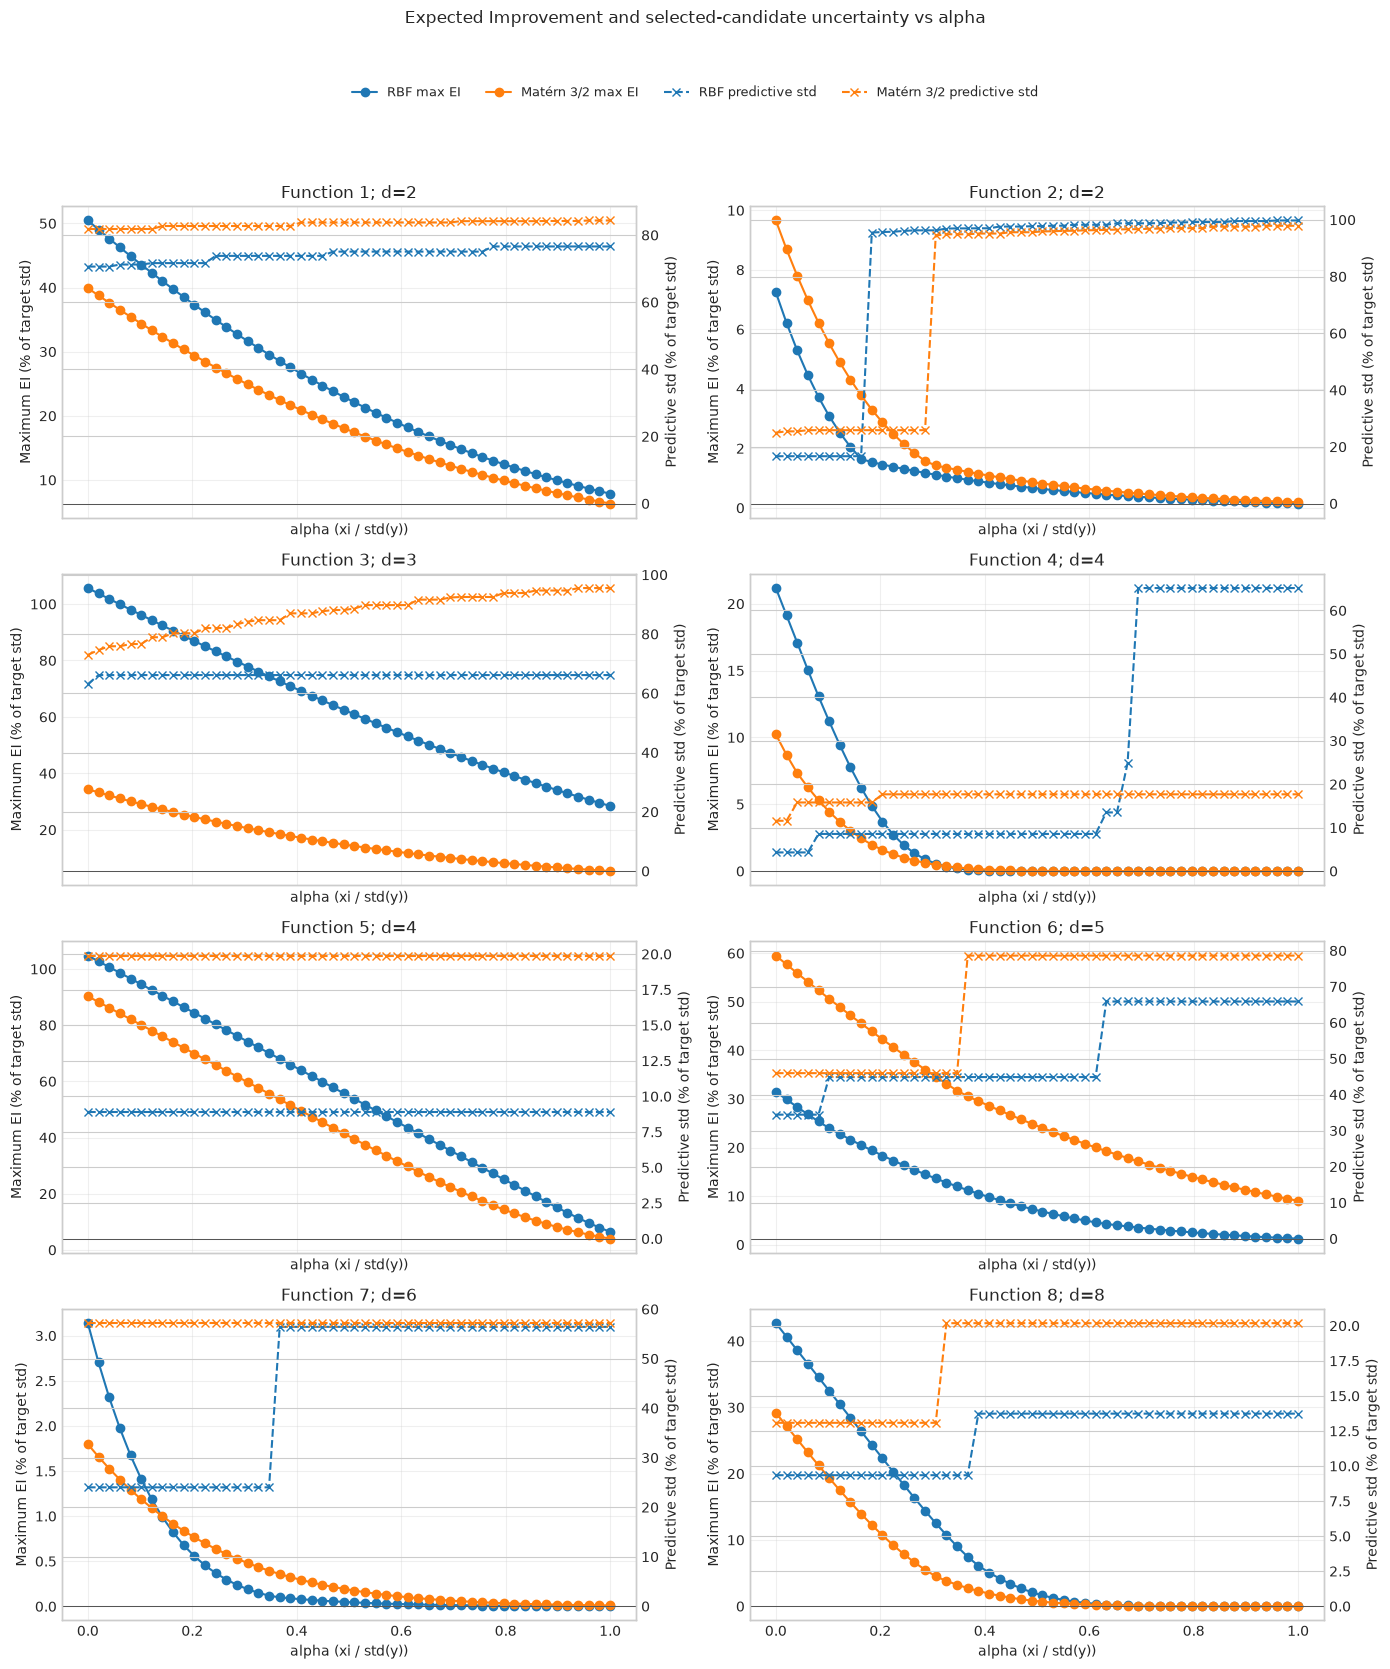

Best candidate by function, kernel, and alpha


,function_id,kernel,alpha,xi,max_ei,max_ei_%_of_target_std,std_%_of_target_std,mean,std
0,1,Matérn 3/2,0.000000,0.000000,4.136994e-04,39.906563,81.809773,0.000141,0.000848
1,1,Matérn 3/2,0.020408,0.000021,4.018250e-04,38.761124,81.809773,0.000141,0.000848
2,1,Matérn 3/2,0.040816,0.000042,3.901590e-04,37.635791,81.809773,0.000141,0.000848
3,1,Matérn 3/2,0.061224,0.000063,3.787021e-04,36.530629,81.809773,0.000141,0.000848
4,1,Matérn 3/2,0.081633,0.000085,3.674549e-04,35.445690,81.809773,0.000141,0.000848
...,...,...,...,...,...,...,...,...,...
795,8,RBF,0.918367,0.888802,2.513058e-06,0.000260,13.732024,9.985559,0.132900
796,8,RBF,0.938776,0.908554,1.327382e-06,0.000137,13.732024,9.985559,0.132900
797,8,RBF,0.959184,0.928305,6.870925e-07,0.000071,13.732024,9.985559,0.132900
798,8,RBF,0.979592,0.948056,3.485131e-07,0.000036,13.732024,9.985559,0.132900


In [5]:
figure, axes = plt.subplots(4, 2, figsize=(14, 16), sharex=True, sharey=False)
axes = axes.ravel()
right_axes = []
for function_id, ax in zip(FUNCTION_IDS, axes):
    function_results = ei_alpha_results[
        ei_alpha_results["function_id"] == function_id
    ]
    std_ax = ax.twinx()
    right_axes.append(std_ax)
    for kernel_name in kernel_factories:
        kernel_results = function_results[function_results["kernel"] == kernel_name]
        ei_line, = ax.plot(
            kernel_results["alpha"],
            kernel_results["max_ei_%_of_target_std"],
            marker="o",
            linestyle="-",
            label=f"{kernel_name} max EI",
        )
        std_ax.plot(
            kernel_results["alpha"],
            kernel_results["std_%_of_target_std"],
            marker="x",
            linestyle="--",
            color=ei_line.get_color(),
            label=f"{kernel_name} predictive std",
        )
    std_ax.axhline(0.0, color="black", linewidth=0.7, alpha=0.6)
    ax.set_title(f"Function {function_id}; d={FUNCTION_SPECS[function_id]}")
    ax.set_xlabel("alpha (xi / std(y))")
    ax.set_ylabel("Maximum EI (% of target std)")
    std_ax.set_ylabel("Predictive std (% of target std)")
    ax.grid(True, alpha=0.3)
ei_handles, ei_labels = axes[0].get_legend_handles_labels()
std_handles, std_labels = right_axes[0].get_legend_handles_labels()
figure.legend(
    ei_handles + std_handles,
    ei_labels + std_labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=4,
    fontsize=9,
)
figure.suptitle("Expected Improvement and selected-candidate uncertainty vs alpha", y=1.04)
figure.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

print("Best candidate by function, kernel, and alpha")
display(
    ei_alpha_results[
        [
            "function_id",
            "kernel",
            "alpha",
            "xi",
            "max_ei",
            "max_ei_%_of_target_std",
            "std_%_of_target_std",
            "mean",
            "std",
        ]
    ]
)

## 6. Selected alpha

`selected_alpha` is fixed at `0.1` in the code. The resulting `xi` values match `XI_VALUES` in Notebook 06, which equal 0.1 times the standard deviation of each function's observed outputs. Notebook 06 uses these values with the Matérn 3/2 kernel only. The rationale for this value is not recorded in this notebook.

In [6]:
selected_alpha = 0.1
selected_xi_values = [
    {
        "function_id": function_id,
        "alpha": selected_alpha,
        "xi": float(selected_alpha * np.std(observations.outputs)),
    }
    for function_id, observations in observations_by_function.items()
]
selected_xi_values

[{'function_id': 1, 'alpha': 0.1, 'xi': 0.00010366701219489613},
 {'function_id': 2, 'alpha': 0.1, 'xi': 0.02169598518452902},
 {'function_id': 3, 'alpha': 0.1, 'xi': 0.008514510271522311},
 {'function_id': 4, 'alpha': 0.1, 'xi': 0.7327808565722272},
 {'function_id': 5, 'alpha': 0.1, 'xi': 35.75969037053485},
 {'function_id': 6, 'alpha': 0.1, 'xi': 0.046625804381253966},
 {'function_id': 7, 'alpha': 0.1, 'xi': 0.03342741263225186},
 {'function_id': 8, 'alpha': 0.1, 'xi': 0.09678071263663912}]